plotFluoroAnal.ipynb - Imports fluorescence analysis data as csv and converts data into dataframe for plotting.

In [150]:
from pathlib import Path
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib as mpl
from matplotlib import ticker
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

import scipy.stats as stats
from statsmodels.stats.weightstats import DescrStatsW
import statistics
import math

# GLR GASTRULOIDS

Num rafts for Array 1: 307
    Array  Raft  Time                   Feature          Value
0       1     1     0                Eccen_Hull       0.174524
1       1     1     0                FArea_Hull  137267.000000
2       1     1     0                 Den_Green       0.995862
3       1     1     0              Radius_Green     214.804615
4       1     1     0        IntMean_Fold_Green       1.000000
5       1     1     0  IntMean_PerPx_Fold_Green       1.000000
6       1     1     6                Eccen_Hull       0.174524
7       1     1     6                FArea_Hull  137267.000000
8       1     1     6                 Den_Green       0.997392
9       1     1     6              Radius_Green     214.571062
10      1     1     6        IntMean_Fold_Green       1.087217
11      1     1     6  IntMean_PerPx_Fold_Green       1.085549
12      1     1    12                Eccen_Hull       0.174524
13      1     1    12                FArea_Hull  137267.000000
14      1     1    12       

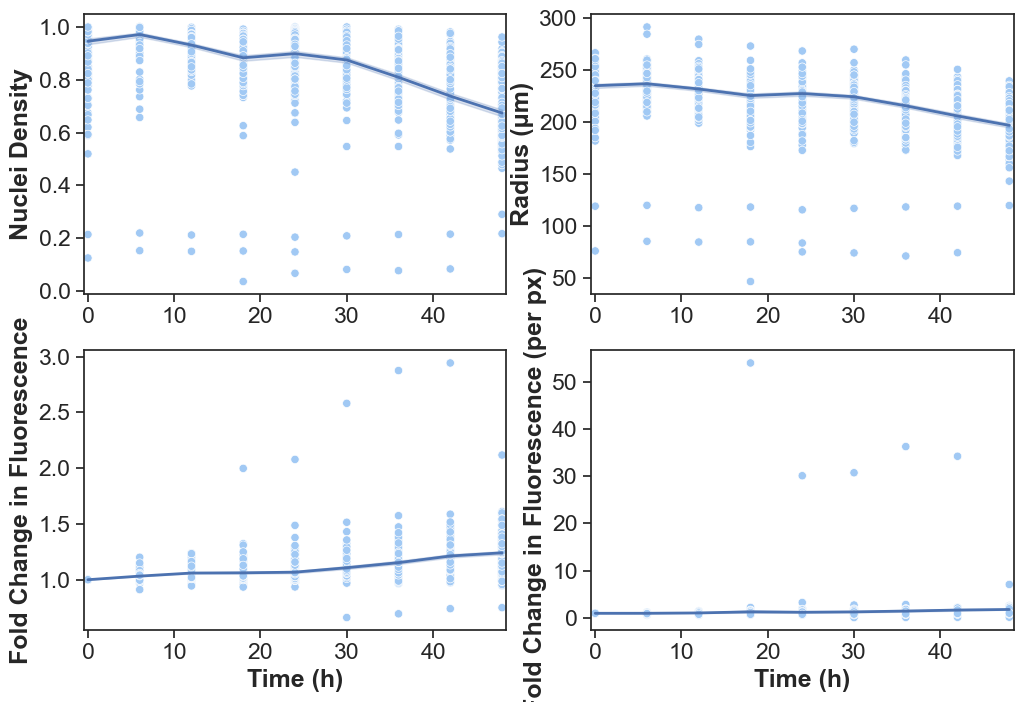

In [176]:
pxSize = 1.0257 # um/px

dataPaths = [Path(r'C:\Users\MVX\Documents\2 - Data\240722_R2GLR_1.8e6_0-48hrBMP4_0%aneu_2_Analysis'),
             Path(r'C:\Users\MVX\Documents\2 - Data\240729_R2GLR_1.8e6_0-48hrBMP4_0%aneu_3_Analysis')
            ]
arrNums = [1, 1]
numTP = [9, 9]
intervals = [6, 6] # hrs
offset = 0 # hrs
time_lim = [-0.5, 48.5]

arrays = []
rafts = []
times = []
features = []
ft_types = ['Eccen_Hull', 'FArea_Hull', 
            'Den_Green', 'Radius_Green', 'IntMean_Fold_Green', 'IntMean_PerPx_Fold_Green']
values = []

for i in range(len(dataPaths)):
    fluorPath = dataPaths[i] / (f'array{arrNums[i]}_fluorAnalysis_GLR.csv')
    df_fluor = pd.read_csv(str(fluorPath))
    df_fluor = df_fluor[(df_fluor['Missing'] == 0) 
                        & (df_fluor['Empty'] == 0) 
                        & (df_fluor['Border'] == 0)
                        & (df_fluor['Eccen_Hull'] <= 0.35)
                       ]
#     df_fluor = df_fluor[(df_fluor['Missing'] == 0) 
#                         & (df_fluor['Empty'] == 0) 
#                         & (df_fluor['Border'] == 0)
#                        ]
#     print(len(df_fluor['Raft'].tolist()))
    numRaft = len(set(df_fluor['Raft'].tolist()))
    print(f'Num rafts for Array {i + 1}: {numRaft}')
    for raft in list(set(df_fluor['Raft'].tolist())):
        for tp in range(numTP[i]):
            time = (tp * intervals[i]) + offset
            for ft in ft_types:
                arrays.append(i + 1)
                rafts.append(raft)
                times.append(time)
                features.append(ft)
                val = df_fluor[(df_fluor['Raft'] == raft) 
                               & (df_fluor['Time'] == time)][f'{ft}'].item()
                if ft == 'Radius_Green':
                    val *= pxSize
                values.append(val)

                
df_final = pd.DataFrame({'Array': arrays,
                        'Raft': rafts,
                        'Time': times,
                        'Feature': features,
                        'Value': values
                        })
print(df_final.head(20))

sns.set_style('white')
plt.rcParams['ytick.left'] = True
plt.rcParams['xtick.bottom'] = True
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.scatterplot(ax=axes[0,0],
                x='Time',
                y='Value',
                data = df_final[df_final['Feature'] == 'Den_Green'],
                hue = 'Array',
                palette='pastel',
                legend=False)
sns.lineplot(ax=axes[0,0],
             x='Time',
             y='Value',
             data = df_final[df_final['Feature'] == 'Den_Green'],
             hue = 'Array',
             linewidth=2,
             legend=False)
axes[0,0].set_xlabel('')
axes[0,0].set_xlim(time_lim[0], time_lim[1])
axes[0,0].set_ylabel(r'Nuclei Density', fontweight='bold')

sns.scatterplot(ax=axes[0,1],
                x='Time',
                y='Value',
                data = df_final[df_final['Feature'] == 'Radius_Green'],
                hue = 'Array',
                palette='pastel',
                legend=False)
sns.lineplot(ax=axes[0,1],
             x='Time',
             y='Value',
             data = df_final[df_final['Feature'] == 'Radius_Green'],
             hue = 'Array',
             linewidth=2,
             legend=False)
axes[0,1].set_xlabel('')
axes[0,1].set_xlim(time_lim[0], time_lim[1])
axes[0,1].set_ylabel(r'Radius (μm)', fontweight='bold')

sns.scatterplot(ax=axes[1,0],
                x='Time',
                y='Value',
                data = df_final[df_final['Feature'] == 'IntMean_Fold_Green'],
                hue = 'Array',
                palette='pastel',
                legend=False)
sns.lineplot(ax=axes[1,0],
             x='Time',
             y='Value',
             data = df_final[df_final['Feature'] == 'IntMean_Fold_Green'],
             hue = 'Array',
             linewidth=2,
             legend=False)
axes[1,0].set_xlabel('Time (h)', fontweight='bold')
axes[1,0].set_xlim(time_lim[0], time_lim[1])
axes[1,0].set_ylabel(r'Fold Change in Fluorescence', fontweight='bold')

sns.scatterplot(ax=axes[1,1],
                x='Time',
                y='Value',
                data = df_final[df_final['Feature'] == 'IntMean_PerPx_Fold_Green'],
                hue = 'Array',
                palette='pastel',
                legend=False)
sns.lineplot(ax=axes[1,1],
             x='Time',
             y='Value',
             data = df_final[df_final['Feature'] == 'IntMean_PerPx_Fold_Green'],
             hue = 'Array',
             linewidth=2,
             legend=False)
axes[1,1].set_xlabel('Time (h)', fontweight='bold')
axes[1,1].set_xlim(time_lim[0], time_lim[1])
axes[1,1].set_ylabel(r'Fold Change in Fluorescence (per px)', fontweight='bold')

sns.set(font_scale=1.25)

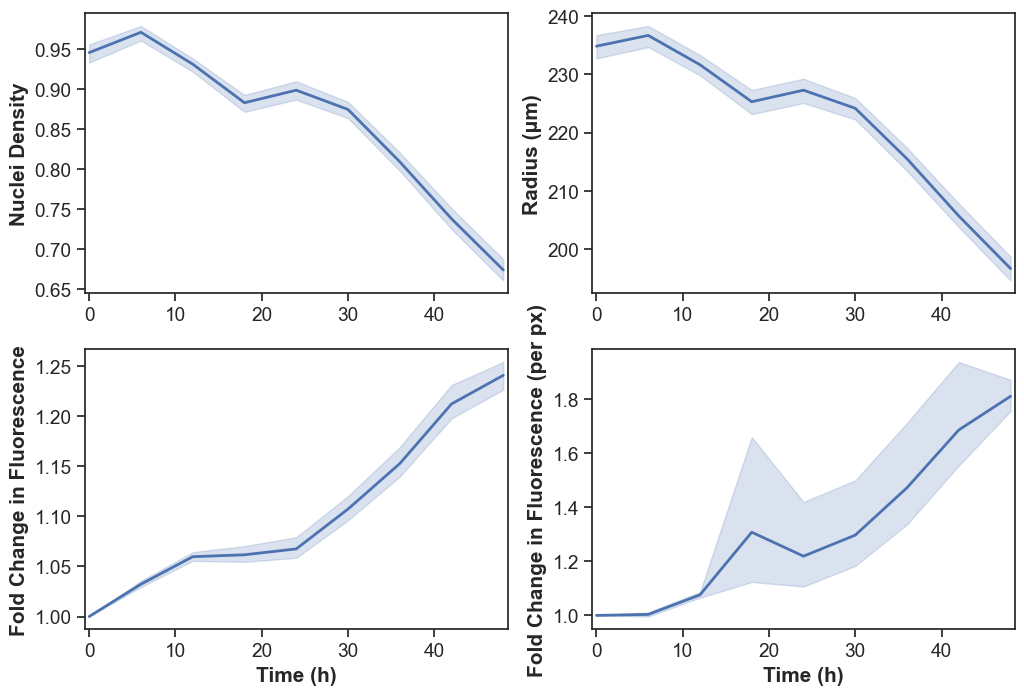

In [157]:
sns.set_style('white')
plt.rcParams['ytick.left'] = True
plt.rcParams['xtick.bottom'] = True
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.lineplot(ax=axes[0,0],
             x='Time',
             y='Value',
             data = df_final[df_final['Feature'] == 'Den_Green'],
             hue = 'Array',
             linewidth=2,
             legend=False)
axes[0,0].set_xlabel('')
axes[0,0].set_xlim(time_lim[0], time_lim[1])
axes[0,0].set_ylabel(r'Nuclei Density', fontweight='bold')

sns.lineplot(ax=axes[0,1],
             x='Time',
             y='Value',
             data = df_final[df_final['Feature'] == 'Radius_Green'],
             hue = 'Array',
             linewidth=2,
             legend=False)
axes[0,1].set_xlabel('')
axes[0,1].set_xlim(time_lim[0], time_lim[1])
axes[0,1].set_ylabel(r'Radius (μm)', fontweight='bold')

sns.lineplot(ax=axes[1,0],
             x='Time',
             y='Value',
             data = df_final[df_final['Feature'] == 'IntMean_Fold_Green'],
             hue = 'Array',
             linewidth=2,
             legend=False)
axes[1,0].set_xlabel('Time (h)', fontweight='bold')
axes[1,0].set_xlim(time_lim[0], time_lim[1])
axes[1,0].set_ylabel(r'Fold Change in Fluorescence', fontweight='bold')

sns.lineplot(ax=axes[1,1],
             x='Time',
             y='Value',
             data = df_final[df_final['Feature'] == 'IntMean_PerPx_Fold_Green'],
             hue = 'Array',
             linewidth=2,
             legend=False)
axes[1,1].set_xlabel('Time (h)', fontweight='bold')
axes[1,1].set_xlim(time_lim[0], time_lim[1])
axes[1,1].set_ylabel(r'Fold Change in Fluorescence (per px)', fontweight='bold')

sns.set(font_scale=1.25)

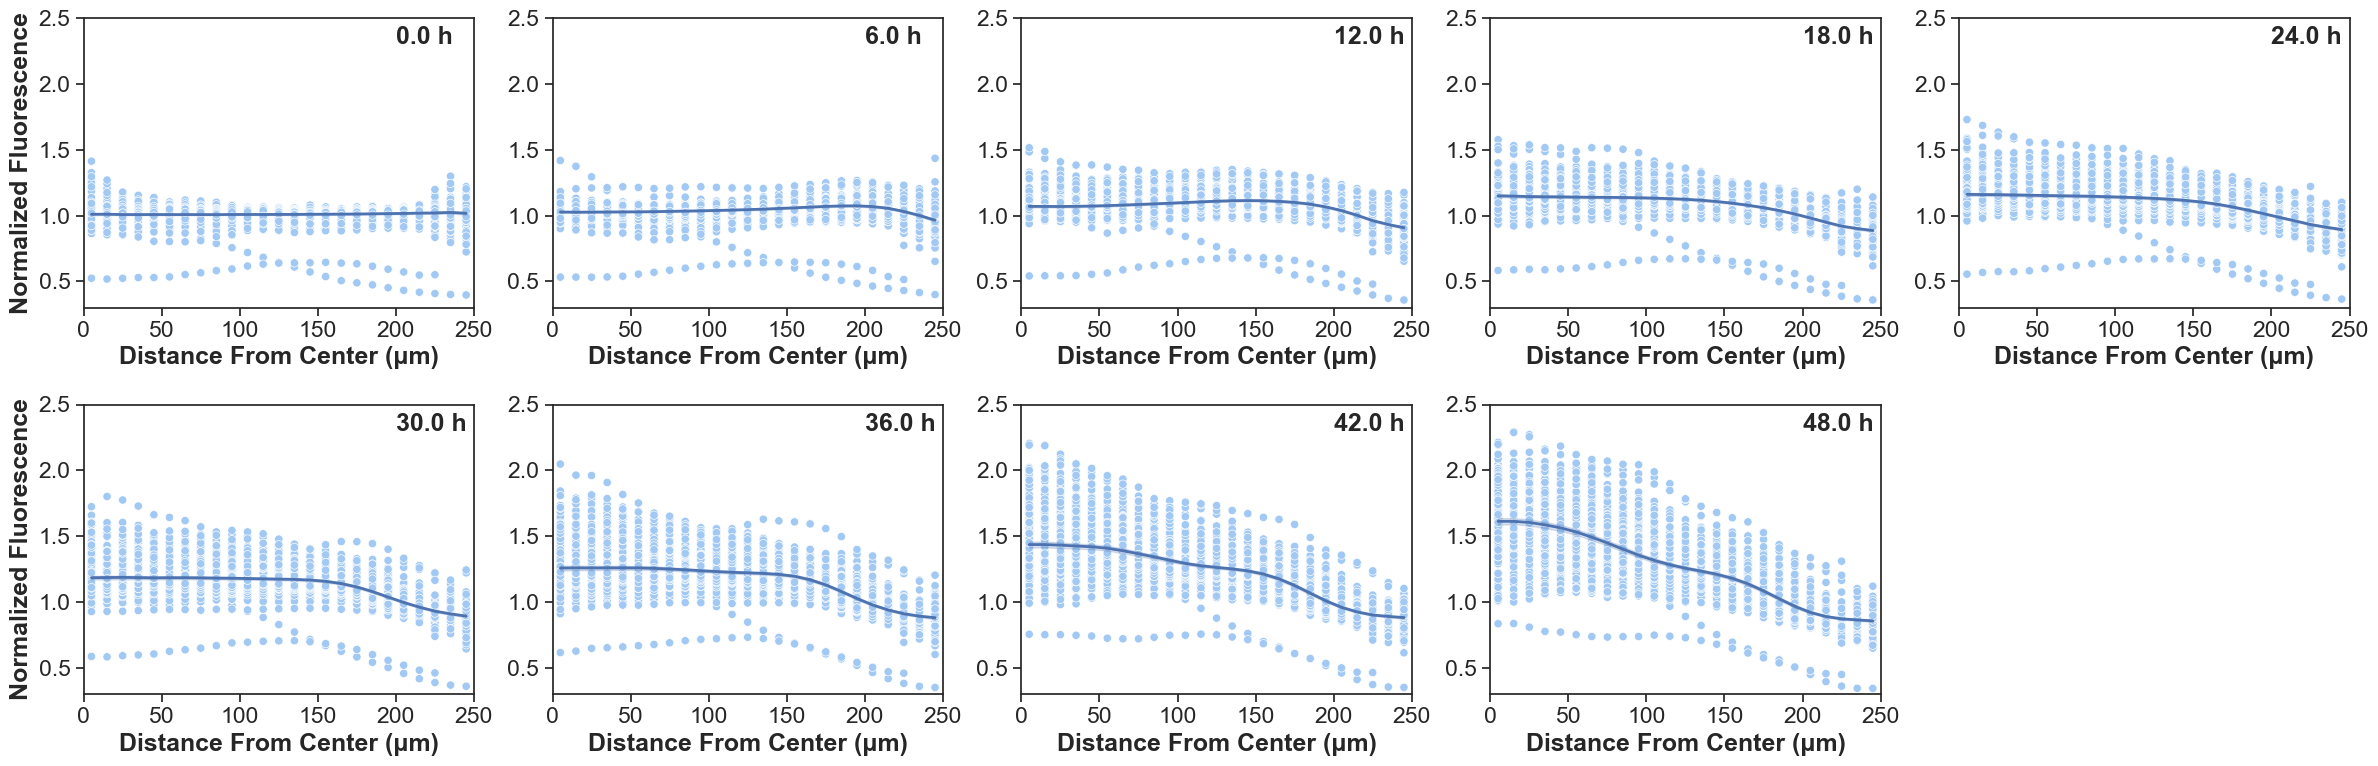

In [183]:
ringWidth = 10 # px
gasRad = math.ceil((500 / 2 / pxSize) / ringWidth) * ringWidth  # px rounded to nearest multiple of ringWidth
numRings = int(gasRad / ringWidth)

arrays = []
rafts = []
times = []
disFromCens = []
values = []
time_set = []

for i in range(len(dataPaths)):
    fluorPath = dataPaths[i] / (f'array{arrNums[i]}_fluorAnalysis_GLR.csv')
    df_fluor_r = pd.read_csv(str(fluorPath))
    df_fluor_r = df_fluor_r[(df_fluor_r['Missing'] == 0) 
                            & (df_fluor_r['Empty'] == 0) 
                            & (df_fluor_r['Border'] == 0)
                            & (df_fluor_r['Eccen_Hull'] <= 0.35)
                           ]
#     print(len(df_fluor_r['Raft'].tolist()))
    time_set = list(set(df_fluor_r['Time'].tolist()))
    time_set.sort()
    for raft in list(set(df_fluor_r['Raft'].tolist())):
        for tp in range(numTP[i]):
            time = (tp * intervals[i]) + offset
            for r in range(numRings):
                arrays.append(i + 1)
                rafts.append(raft)
                times.append(time)
                
                disFromCen = (ringWidth / 2) + (r * (ringWidth))
                disFromCens.append(disFromCen)
                col_name = f'IntMean_fromCenter_{disFromCen}_Green'
                
                val = df_fluor_r[(df_fluor_r['Raft'] == raft) 
                               & (df_fluor_r['Time'] == time)][col_name].item()
                val *= pxSize # um
                values.append(val)
                
df_final = pd.DataFrame({'Array': arrays,
                        'Raft': rafts,
                        'Time': times,
                        'DisFromCen': disFromCens,
                        'Value': values
                        })
# print(df_final.head(20))

sns.set_style('white')
plt.rcParams['ytick.left'] = True
plt.rcParams['xtick.bottom'] = True
fig, axes = plt.subplots(2, (int(numTP[i]/2) + 1), figsize=(24, 8))

# print(time_set)

i = 0 # array num
for tp in range(numTP[i]):
    if tp / (int(numTP[i]/2) + 1) < 1:
        subplot = [0, tp]
    else:
        subplot = [1, tp - (int(numTP[i]/2) + 1)]
#     print(subplot)
    sns.scatterplot(ax=axes[subplot[0], subplot[1]],
                    x='DisFromCen',
                    y='Value',
                    data = df_final[df_final['Time'] == time_set[tp]],
                    hue = 'Array',
                    palette='pastel',
                    legend=False)
    sns.lineplot(ax=axes[subplot[0], subplot[1]],
                 x='DisFromCen',
                 y='Value',
                 data = df_final[df_final['Time'] == time_set[tp]],
                 hue = 'Array',
                 linewidth=2,
                 legend=False)
    axes[subplot[0], subplot[1]].set_xlabel('Distance From Center (μm)', fontweight='bold')
    axes[subplot[0], subplot[1]].set_xlim(0, gasRad)
    axes[subplot[0], subplot[1]].set_ylabel('')
#     axes[subplot[0], subplot[1]].set_ylim(0.8, 1.7)
#     axes[subplot[0], subplot[1]].text(200, 1.4, f'{time_set[tp]} h', fontweight='bold')
    axes[subplot[0], subplot[1]].set_ylim(0.3, 2.5)
    axes[subplot[0], subplot[1]].text(200, 2.3, f'{time_set[tp]} h', fontweight='bold')
    
if numTP[i] % 2 == 1:
    fig.delaxes(axes[1, numTP[i] - (int(numTP[i]/2) + 1)])

axes[0, 0].set_ylabel('Normalized Fluorescence', fontweight='bold')
axes[1, 0].set_ylabel('Normalized Fluorescence', fontweight='bold')

sns.set(font_scale=1.5)
fig.tight_layout()

Text(0, 0.5, 'Hull Eccentricity')

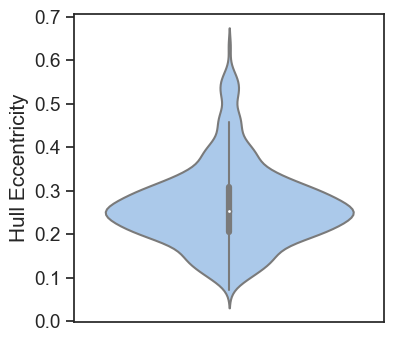

In [144]:
fig, axes = plt.subplots(1, 1, figsize=(4, 4))

sns.set_style('white')
plt.rcParams['ytick.left'] = True
sns.violinplot(y='Value',
              data = df_final[df_final['Feature'] == 'Eccen_Hull'],
              hue = 'Array',
              palette='pastel',
              jitter = 0.3,
              legend=False)
axes.set_ylabel('Hull Eccentricity')

Text(0, 0.5, 'Hull FArea')

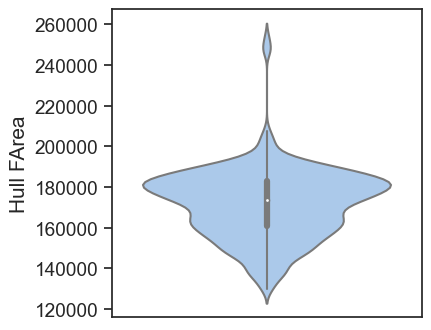

In [178]:
fig, axes = plt.subplots(1, 1, figsize=(4, 4))

sns.set_style('white')
plt.rcParams['ytick.left'] = True
sns.violinplot(y='Value',
              data = df_final[df_final['Feature'] == 'FArea_Hull'],
              hue = 'Array',
              palette='pastel',
              jitter = 0.3,
              legend=False)
axes.set_ylabel('Hull FArea')

# FIXED GASTRULOIDS

462
225
159


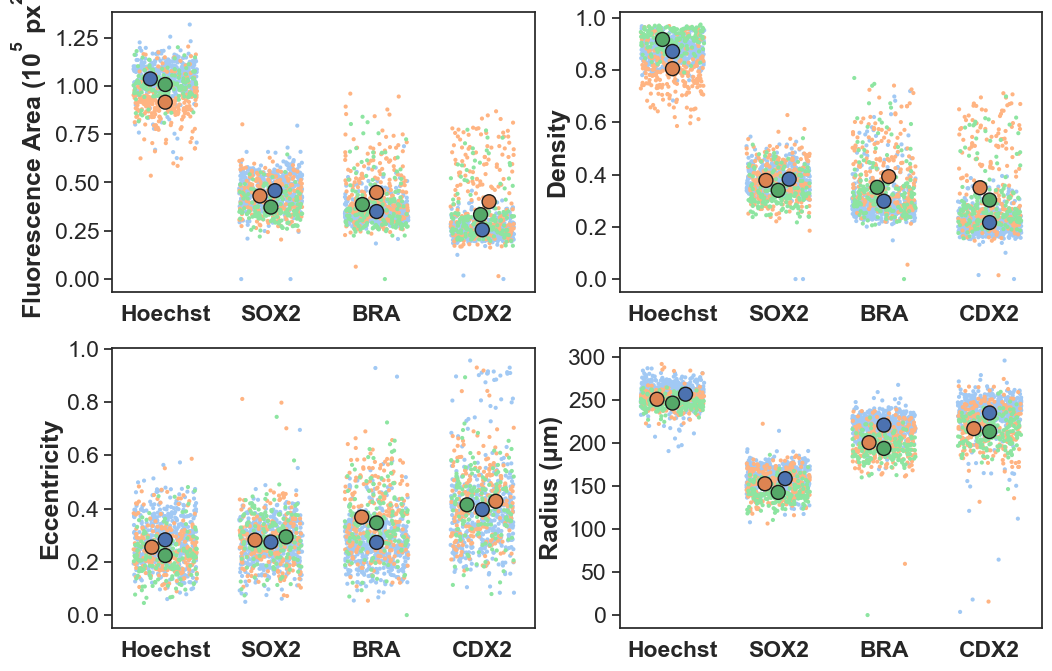

In [184]:
dataPaths = [Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\231019_RUES2_1.8e6_48hrBMP4_0%aneu_1_Analysis'),
          Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\231019_RUES2_1.8e6_48hrBMP4_0%aneu_2_Analysis'),
          Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\231019_RUES2_1.8e6_48hrBMP4_0%aneu_3_Analysis')]
arrNums = ['1', '1', '1']
pxSize = 1.3163 # um/px

arrays = []
rafts = []
channels = []
ch_types = ['Blue', 'Green', 'Red', 'FarRed']
features = []
ft_types = ['FArea', 'Dens', 'Eccen', 'Radius']
values = []

for i in range(len(dataPaths)):
    fluorPath = dataPaths[i] / (f'array{arrNums[i]}_fluorAnalysis_Fixed.csv')
    df_fluor = pd.read_csv(str(fluorPath))
    df_fluor = df_fluor[(df_fluor['Missing'] == 0) 
                        & (df_fluor['Empty'] == 0) 
                        & (df_fluor['Border'] == 0)
                        & (df_fluor['Lo_Int'] == 0)
                       ]
#     df_fluor = df_fluor[(df_fluor['Missing'] == 0) 
#                         & (df_fluor['Empty'] == 0) 
#                         & (df_fluor['Border'] == 0)
#                        ]
    print(len(df_fluor['Raft'].tolist()))
    for raft in df_fluor['Raft'].tolist():
        for ch in ch_types:
            for ft in ft_types:
                arrays.append(i + 1)
                rafts.append(raft)
                channels.append(ch)
                features.append(ft)
                col_name = f'{ft}_{ch}'
                val = df_fluor[df_fluor['Raft'] == raft][col_name].item()
                if (ft == 'Radius'):
                    val = df_fluor[df_fluor['Raft'] == raft][col_name].item() * pxSize
                values.append(val)
                
df_final = pd.DataFrame({'Array': arrays,
                        'Raft': rafts,
                        'Channel': channels,
                        'Feature': features,
                        'Value': values
                        })

arr_mean = []
ch_mean = []
ft_mean = []
val_mean = []
for i in range(len(dataPaths)):
    for ch in ch_types:
        for ft in ft_types:
            arr_mean.append(i + 1)
            ch_mean.append(ch)
            ft_mean.append(ft)
            df_arr = df_final[(df_final['Array'] == (i + 1)) 
                              & (df_final['Channel'] == ch)
                              & (df_final['Feature'] == ft)
                             ]
#             print(f'Array{i+1}_{ch}_{ft}')
            mean_list = [x for x in df_arr['Value'].tolist() if not math.isnan(x)]
#             print(mean_list)
            mean = statistics.mean(mean_list)
#             print(mean)
#             print()
            val_mean.append(mean)
df_mean = pd.DataFrame({'Array': arr_mean,
                        'Channel': ch_mean,
                        'Feature': ft_mean,
                        'Mean': val_mean
                       })

sns.set_style('white')
plt.rcParams['ytick.left'] = True
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.stripplot(ax=axes[0,0],
              x='Channel',
              y='Value',
              data = df_final[df_final['Feature'] == 'FArea'],
              hue='Array',
              size=3,
              palette='pastel',
              jitter=0.3,
              legend=False)
sns.swarmplot(ax=axes[0,0],
              x='Channel',
              y='Mean',
              data=df_mean[df_mean['Feature'] == 'FArea'],
              hue='Array',
              size=10,
              palette='deep',
              edgecolor='k',
              linewidth=1,
              legend=False)
axes[0,0].set_xlabel('')
axes[0,0].set_xticks([0, 1, 2, 3], ['Hoechst', 'SOX2', 'BRA', 'CDX2'], fontweight='bold')
axes[0,0].set_ylabel(r'Fluorescence Area ($\mathregular{10^5}$ $\mathregular{px^2}$)', fontweight='bold')
axes[0,0].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
axes[0,0].yaxis.get_offset_text().set_visible(False)

sns.stripplot(ax=axes[0,1],
              x='Channel',
              y='Value',
              data = df_final[df_final['Feature'] == 'Dens'],
              hue='Array',
              size=3,
              palette='pastel',
              jitter=0.3,
              legend=False)
sns.swarmplot(ax=axes[0,1],
              x='Channel',
              y='Mean',
              data=df_mean[df_mean['Feature'] == 'Dens'],
              hue='Array',
              size=10,
              palette='deep',
              edgecolor='k',
              linewidth=1,
              legend=False)
axes[0,1].set_xlabel('')
axes[0,1].set_xticks([0, 1, 2, 3], ['Hoechst', 'SOX2', 'BRA', 'CDX2'], fontweight='bold')
axes[0,1].set_ylabel('Density', fontweight='bold')

sns.stripplot(ax=axes[1,0],
              x='Channel',
              y='Value',
              data = df_final[df_final['Feature'] == 'Eccen'],
              hue='Array',
              size=3,
              palette='pastel',
              jitter=0.3,
              legend=False)
sns.swarmplot(ax=axes[1,0],
              x='Channel',
              y='Mean',
              data=df_mean[df_mean['Feature'] == 'Eccen'],
              hue='Array',
              size=10,
              palette='deep',
              edgecolor='k',
              linewidth=1,
              legend=False)
axes[1,0].set_xlabel('')
axes[1,0].set_xticks([0, 1, 2, 3], ['Hoechst', 'SOX2', 'BRA', 'CDX2'], fontweight='bold')
axes[1,0].set_ylabel('Eccentricity', fontweight='bold')

sns.stripplot(ax=axes[1,1],
              x='Channel',
              y='Value',
              data = df_final[df_final['Feature'] == 'Radius'],
              hue='Array',
              size=3,
              palette='pastel',
              jitter=0.3,
              legend=False)
sns.swarmplot(ax=axes[1,1],
              x='Channel',
              y='Mean',
              data=df_mean[df_mean['Feature'] == 'Radius'],
              hue='Array',
              size=10,
              palette='deep',
              edgecolor='k',
              linewidth=1,
              legend=False)
axes[1,1].set_xlabel('')
axes[1,1].set_xticks([0, 1, 2, 3], ['Hoechst', 'SOX2', 'BRA', 'CDX2'], fontweight='bold')
axes[1,1].set_ylabel('Radius (μm)', fontweight='bold')

sns.set(font_scale=1.25)

Min threshold values for Arrays 1 & 2: [1500.0, 221.0, 330.0, 217.0]
Min threshold values for Array 3: [1500.0, 161.0, 212.0, 162.0]


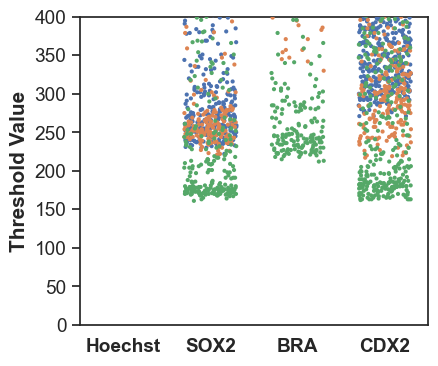

In [18]:
dataPaths = [Path(r'C:\Users\MVX\Documents\2 - Data\231019_RUES2_1.8e6_48hrBMP4_0%aneu_1_Analysis'),
            Path(r'C:\Users\MVX\Documents\2 - Data\231019_RUES2_1.8e6_48hrBMP4_0%aneu_2_Analysis'),
            Path(r'C:\Users\MVX\Documents\2 - Data\231019_RUES2_1.8e6_48hrBMP4_0%aneu_3_Analysis')]
arrNums = ['1', '1', '1']

arrays = []
rafts = []
channels = []
ch_types = ['Blue', 'Green', 'Red', 'FarRed']
features = []
ft_types = ['FArea', 'ThreshVal', 'Dens', 'Eccen', 'Radius']
values = []

for i in range(len(dataPaths)):
    fluorPath = dataPaths[i] / (f'array{arrNums[i]}_fluorAnalysis_Fixed.csv')
    df_fluor = pd.read_csv(str(fluorPath))
    df_fluor = df_fluor[(df_fluor['Missing'] == 0) 
                        & (df_fluor['Empty'] == 0) 
                        & (df_fluor['Border'] == 0)
                       ]
#     print(len(df_fluor['Raft'].tolist()))
    for raft in df_fluor['Raft'].tolist():
        for ch in ch_types:
            for ft in ft_types:
                arrays.append(i + 1)
                rafts.append(raft)
                channels.append(ch)
                features.append(ft)
                col_name = f'{ft}_{ch}'
                val = df_fluor[df_fluor['Raft'] == raft][col_name].item()
                values.append(val)
                
df_final = pd.DataFrame({'Array': arrays,
                        'Raft': rafts,
                        'Channel': channels,
                        'Feature': features,
                        'Value': values
                        })
min_thresh1 = []
for ch in ch_types:
    df_sub = df_final[(df_final['Channel']==ch)
                      & (df_final['Feature']=='ThreshVal')
                     & (df_final['Array']!=3)]
    min_thresh1.append(min(df_sub['Value'].tolist()))
min_thresh2 = []
for ch in ch_types:
    df_sub = df_final[(df_final['Channel']==ch)
                      & (df_final['Feature']=='ThreshVal')
                     & (df_final['Array']==3)]
    min_thresh2.append(min(df_sub['Value'].tolist()))
print(f'Min threshold values for Arrays 1 & 2: {min_thresh1}')
print(f'Min threshold values for Array 3: {min_thresh2}')
 
fig = plt.figure(figsize=(4.5, 4))
sns.set_style('white')
plt.rcParams['ytick.left'] = True

sns.stripplot(x='Channel',
              y='Value',
              data = df_final[df_final['Feature'] == 'ThreshVal'],
              hue='Array',
              size=3,
              palette='deep',
              jitter=0.3,
              legend=False)
plt.xlabel('')
plt.xticks([0, 1, 2, 3], ['Hoechst', 'SOX2', 'BRA', 'CDX2'], fontweight='bold')
plt.ylabel('Threshold Value', fontweight='bold')
plt.ylim(0, 400)

sns.set(font_scale=1.25)

Pass vs Exclude Means: [0.9094202898550725, 0.09057971014492754]
Pass vs Exclude Stdev: [0.09294955230112156, 0.09294955230112155]

Excluded Type Means: [0.050434782608695654, 0.25565217391304346, 0.6956521739130435]
1.0017391304347827
Excluded Type SE: [0.003645705535186005, 0.014528445686234624, 0.014520397644218155]


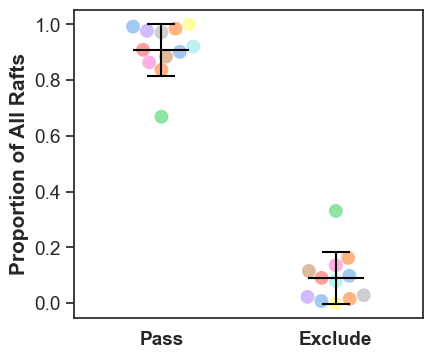

In [5]:
exclude_list = [52, 8, 175, 48, 12, 61, 72, 15, 0, 42, 4, 86]
numArr = len(exclude_list)
pass_list = []
for ex in exclude_list:
    pass_list.append(529 - ex)
# print(sum(pass_list),sum(exclude_list))
missing_list = [4, 5, 10, 6, 0, 0, 0, 0, 0, 2, 2, 0]
empty_list = [13, 3, 1, 0, 8, 1, 3, 8, 0, 37, 1, 72]
border_list = [36, 0, 164, 42, 4, 60, 69, 7, 0, 3, 1, 14]

arrays = []
pers = []
types = []

for i in range(numArr):
    arrays.append(i + 1)
    pers.append(pass_list[i] / 529)
    types.append('Pass')
    arrays.append(i + 1)
    pers.append(exclude_list[i] / 529)
    types.append('Exclude')
    arrays.append(i + 1)
    if exclude_list[i] == 0:
        pers.append(-1)
        types.append('Missing')
        arrays.append(i + 1)
        pers.append(-1)
        types.append('Empty')
        arrays.append(i + 1)
        pers.append(-1)
        types.append('Border')
    else:
        pers.append(missing_list[i] / exclude_list[i])
        types.append('Missing')
        arrays.append(i + 1)
        pers.append(empty_list[i] / exclude_list[i])
        types.append('Empty')
        arrays.append(i + 1)
        pers.append(border_list[i] / exclude_list[i])
        types.append('Border')

# Set 6 EU has 0 excluded rafts
exclude_list2 = exclude_list
del exclude_list2[8]
numArr_adj = list(range(numArr))
del numArr_adj[8]

df = pd.DataFrame({'Array': arrays,
                   'Type': types,
                   'Per': pers}) 
pass_list_per = df[df['Type']=='Pass']['Per'].tolist()
exclude_list_per = df[df['Type']=='Exclude']['Per'].tolist()

passex_mean = [statistics.mean(pass_list_per), 
               statistics.mean(exclude_list_per)]
passex_stdev = [statistics.stdev(pass_list_per), 
                statistics.stdev(exclude_list_per)]
print(f'Pass vs Exclude Means: {passex_mean}')
print(f'Pass vs Exclude Stdev: {passex_stdev}')
print()

# Automated weighted average
missing_list2 = missing_list
empty_list2 = empty_list
border_list2 = border_list
del missing_list2[8]
del empty_list2[8]
del border_list2[8]
for i in range(numArr - 1):
    missing_list2[i] = missing_list2[i] / exclude_list2[i]
    empty_list2[i] = empty_list2[i] / exclude_list2[i]
    border_list2[i] = border_list2[i] / exclude_list2[i]
missing_w = DescrStatsW(missing_list2, weights=exclude_list2, ddof=0)
empty_w = DescrStatsW(empty_list2, weights=exclude_list2, ddof=0)
border_w = DescrStatsW(border_list2, weights=exclude_list2, ddof=0)
ex_mean = [missing_w.mean, empty_w.mean, border_w.mean]
ex_se = [missing_w.std_mean, empty_w.std_mean, border_w.std_mean]
print(f'Excluded Type Means: {ex_mean}')
print(sum(ex_mean))
print(f'Excluded Type SE: {ex_se}')

# # Manual weighted average
# missing = 0
# empty = 0
# border = 0
# for i in numArr_adj:
#     print(i)
#     missing += missing_list[i]
#     empty += empty_list[i]
#     border += border_list[i]
# ex_mean = [missing, empty, border]
# for i in range(len(ex_mean)):
#     ex_mean[i] = ex_mean[i] / sum(exclude_list2)
# print(ex_mean)

fig = plt.figure(figsize=(4.5, 4))
sns.set_style('white')
plt.rcParams['ytick.left'] = True

# Pass vs exclude
df_passex = df[(df['Type'] == 'Pass') | (df['Type'] == 'Exclude')]
sns.swarmplot(x='Type',
              y='Per',
              data=df_passex,
              hue='Array',
              size=10,
              palette='pastel',
              legend=False,
              zorder=1)
for i in range(2):
    plt.errorbar(x=i,
                 y=passex_mean[i],
                 yerr=passex_stdev[i],
                 color='black',
                 capsize=10,
                 capthick=1.5,
                 marker='_',
                 markersize=40,
                 markeredgewidth=1.5,
                 zorder=2,
                 linewidth=1.5)
plt.xticks([0, 1],['Pass', 'Exclude'], fontweight='bold')
plt.xlim(-0.5, 1.5)
plt.xlabel('')
plt.ylabel('Proportion of All Rafts', fontweight='bold')

sns.set(font_scale=1.25)
# fig.tight_layout()

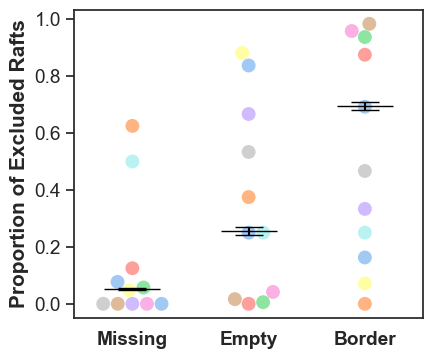

In [6]:
fig = plt.figure(figsize=(4.5, 4))
sns.set_style('white')
plt.rcParams['ytick.left'] = True

# Excluded rafts
df_ex = df[((df['Type'] == 'Missing') | (df['Type'] == 'Empty') | (df['Type'] == 'Border')) &
           (df['Per'] > -1)
          ]
sns.swarmplot(x='Type',
              y='Per',
              data= df_ex,
              hue='Array',
              size=10,
              palette='pastel',
              legend=False,
              zorder=1)
for i in range(3):
    plt.errorbar(x=i,
                 y=ex_mean[i],
                 yerr=ex_se[i],
                 color='black',
                 capsize=10,
                 capthick=0.75,
                 marker='_',
                 markersize=40,
                 markeredgewidth=1,
                 zorder=2,
                 linewidth=1.5)
plt.xticks([0, 1, 2],['Missing', 'Empty', 'Border'], fontweight='bold')
plt.xlim(-0.5, 2.5)
plt.xlabel('')
plt.ylabel('Proportion of Excluded Rafts', fontweight='bold')
# sns.scatterplot(x=[0, 1, 2],
#                 y=ex_mean,
#                 c='k',
#                 marker='^',
#                 s=100,
#                 legend=False
#                )

sns.set(font_scale=1.25)
# fig.tight_layout()

# CALC & HOECHST GASTRULOIDS

Eu_1: 477
An_1: 521
Eu_2: 354
An_2: 481
Eu_3: 517
An_3: 468
Eu_4: 457
An_4: 514
Eu_5: 529
An_5: 487
Eu_6: 525
An_6: 443
[0.9637249418227819, 0.962588878883566, 0.9050180193229528, 0.9127154772897249, 0.866450687620837, 0.9525446675513947]
[0.5502677497487152, 0.21936522923969523, 0.4919712804164519, 0.4253173178022891, 0.334999314759146, 0.4755523824044456]
Ttest_indResult(statistic=9.876822106496778, pvalue=1.780577601690743e-06)
Weighted Means: [0.9247628239599598, 0.4169094732881001]
Weighted SE: [0.0006731436014002829, 0.0020450323471148807]


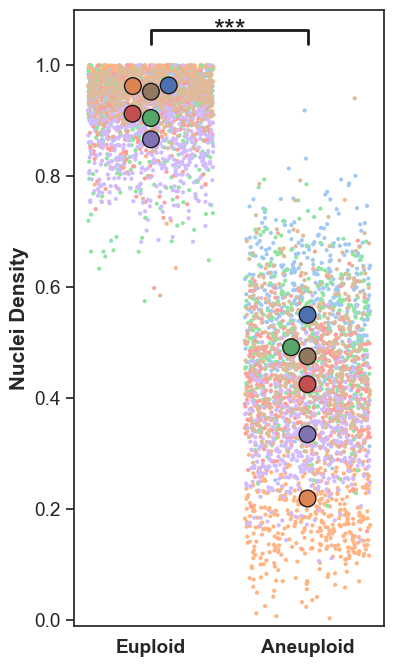

In [189]:
dataPaths = [Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\240221_RUES2_1.8e6_48hrBMP4_0&100%aneu_2_Analysis'),
             Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\240424_RUES2_1.8e6_48hrBMP4_0&100%aneu_3_Analysis'),
             Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\240501_RUES2_1.8e6_48hrBMP4_0&100%aneu_4_Analysis'),
             Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\240605_RUES2_1.8e6_48hrBMP4_0&100%aneu_5_Analysis'),
             Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\240612_RUES2_1.8e6_48hrBMP4_0&100%aneu_6_Analysis'),
             Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\240619_RUES2_1.8e6_48hrBMP4_0&100%aneu_7_Analysis')
            ]

exclude_list = [52, 8, 175, 48, 12, 61, 72, 15, 0, 42, 4, 86]
numArr = len(exclude_list)
pass_list = []
for ex in exclude_list:
    pass_list.append(529 - ex)

nucDen = []
nucDen_ploid = []
nucDen_rep = []
eu_nucDen_mean = []
an_nucDen_mean = []
for i in range(len(dataPaths)):
    eu = pd.read_csv(str(dataPaths[i] / r'array1_fluorAnalysis_CalcHoechst.csv'))
    eu = eu[(eu['Missing'] == 0) & (eu['Empty'] == 0) & (eu['Border'] == 0)]
    nucDen.extend(eu['NucDen'].tolist())
    for j in range(len(eu['NucDen'].tolist())):
        nucDen_ploid.append('Euploid')
        nucDen_rep.append(i + 1)
    
    an = pd.read_csv(str(dataPaths[i] / r'array2_fluorAnalysis_CalcHoechst.csv'))
    an = an[(an['Missing'] == 0) & (an['Empty'] == 0) & (an['Border'] == 0)]
    nucDen.extend(an['NucDen'].tolist())
    for j in range(len(an['NucDen'].tolist())):
        nucDen_ploid.append('Aneuploid')
        nucDen_rep.append(i + 1)
    
    eu_nucDen_mean.append(statistics.mean(eu['NucDen'].tolist()))
    l_eu = len(eu['NucDen'].tolist())
    print(f'Eu_{i + 1}: {l_eu}')
    an_nucDen_mean.append(statistics.mean(an['NucDen'].tolist()))
    l_an = len(an['NucDen'].tolist())
    print(f'An_{i + 1}: {l_an}')
    
print(eu_nucDen_mean)
print(an_nucDen_mean)
print(stats.ttest_ind(a=eu_nucDen_mean, b=an_nucDen_mean, equal_var=True))

df_raw = pd.DataFrame({'Replicate': nucDen_rep,
                      'Ploidy': nucDen_ploid,
                      'NucDen': nucDen,
                      })
means = eu_nucDen_mean + an_nucDen_mean
replicates = list(range(1, len(dataPaths)+1)) + list(range(1, len(dataPaths)+1))
ploidies = ['Euploid'] * len(dataPaths) + ['Aneuploid'] * len(dataPaths)
df_mean = pd.DataFrame({'Replicate': replicates,
                       'Ploidy': ploidies,
                       'Mean': means})

eu_sizes = pass_list[0::2]
an_sizes = pass_list[1::2]
eu_w = DescrStatsW(eu_nucDen_mean, weights=eu_sizes, ddof=0)
an_w = DescrStatsW(an_nucDen_mean, weights=an_sizes, ddof=0)
weight_mean = [eu_w.mean, an_w.mean]
weight_se = [eu_w.std_mean, an_w.std_mean]
print(f'Weighted Means: {weight_mean}')
print(f'Weighted SE: {weight_se}')

fig = plt.figure(figsize=(4, 8))
sns.set_style('white')
plt.rcParams['ytick.left'] = True

sns.stripplot(x='Ploidy',
              y='NucDen',
              data = df_raw,
              hue='Replicate',
              size=3,
              palette='pastel',
              jitter=0.4,
              legend=False,
              zorder=1)
sns.swarmplot(x='Ploidy',
              y='Mean',
              data=df_mean,
              hue='Replicate',
              size=12,
              palette='deep',
              edgecolor='k',
              linewidth=1,
              legend=False,
              zorder=2)
# for i in range(2):
#     plt.errorbar(x=i,
#                  y=weight_mean[i],
#                  yerr=weight_se[i],
#                  color='black',
#                  capsize=10,
#                  capthick=0.75,
#                  marker='_',
#                  markersize=40,
#                  markeredgewidth=1,
#                  linewidth=1.5,
#                  zorder=i+2)

plt.xticks([0, 1],['Euploid', 'Aneuploid'], fontweight='bold')
plt.xlabel('')
plt.ylabel('Nuclei Density', fontweight='bold')
plt.ylim(-0.01, 1.1)
plt.plot([0, 0, 1, 1], [max(means)+0.075, max(means)+0.1, max(means)+0.1, max(means)+0.075], linewidth=2, color='k')
plt.text((0+1)*.5, max(means)+0.075, "***", ha='center', va='bottom', color='k', fontsize=20)

sns.set(font_scale=1.25)
# plt.tight_layout

[96758.23689727463, 119718.197740113, 92540.77176015473, 107266.01531728666, 108862.37996219282, 106888.84571428571]
[100211.14587332054, 99311.7234927235, 114581.61324786325, 102332.70038910506, 80887.99178644764, 69963.32505643342]
Ttest_indResult(statistic=1.404697317434104, pvalue=0.19040354603991408)


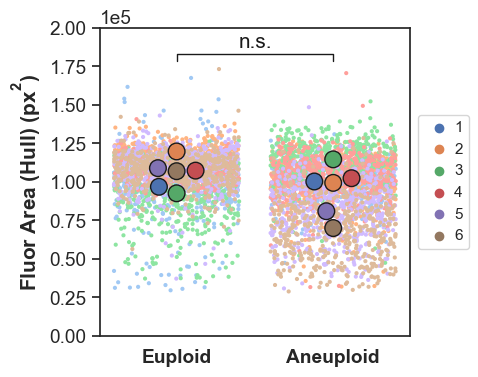

In [81]:
dataPaths = [Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\240221_RUES2_1.8e6_48hrBMP4_0&100%aneu_2_Analysis'),
             Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\240424_RUES2_1.8e6_48hrBMP4_0&100%aneu_3_Analysis'),
             Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\240501_RUES2_1.8e6_48hrBMP4_0&100%aneu_4_Analysis'),
             Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\240605_RUES2_1.8e6_48hrBMP4_0&100%aneu_5_Analysis'),
             Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\240612_RUES2_1.8e6_48hrBMP4_0&100%aneu_6_Analysis'),
             Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\240619_RUES2_1.8e6_48hrBMP4_0&100%aneu_7_Analysis')
            ]

fArea_hull = []
hull_ploid = []
hull_rep = []
eu_hull_mean = []
an_hull_mean = []
for i in range(len(dataPaths)):
    eu = pd.read_csv(str(dataPaths[i] / r'array1_fluorAnalysis_CalcHoechst.csv'))
    eu = eu[(eu['Missing'] == 0) & (eu['Empty'] == 0) & (eu['Border'] == 0)]
    fArea_hull.extend(eu['FArea_Hull'].tolist())
    for j in range(len(eu['FArea_Hull'].tolist())):
        hull_ploid.append('Euploid')
        hull_rep.append(i + 1)
    
    an = pd.read_csv(str(dataPaths[i] / r'array2_fluorAnalysis_CalcHoechst.csv'))
    an = an[(an['Missing'] == 0) & (an['Empty'] == 0) & (an['Border'] == 0)]
    fArea_hull.extend(an['FArea_Hull'].tolist())
    for j in range(len(an['FArea_Hull'].tolist())):
        hull_ploid.append('Aneuploid')
        hull_rep.append(i + 1)
    
    eu_hull_mean.append(statistics.mean(eu['FArea_Hull'].tolist()))
    an_hull_mean.append(statistics.mean(an['FArea_Hull'].tolist()))
    
df_raw = pd.DataFrame({'Replicate': hull_rep,
                      'Ploidy': hull_ploid,
                      'FArea_Hull': fArea_hull,
                      })
    
print(eu_hull_mean)
print(an_hull_mean)
print(stats.ttest_ind(a=eu_hull_mean, b=an_hull_mean, equal_var=True))
means = eu_hull_mean + an_hull_mean
replicates = list(range(1, len(dataPaths)+1)) + list(range(1, len(dataPaths)+1))
ploidies = ['Euploid'] * len(dataPaths) + ['Aneuploid'] * len(dataPaths)
df_mean = pd.DataFrame({'Replicate': replicates,
                       'Ploidy': ploidies,
                       'Mean': means})

fig = plt.figure(figsize=(4, 4))
sns.set_style('white')
plt.rcParams['ytick.left'] = True

sns.stripplot(x='Ploidy',
              y='FArea_Hull',
              data = df_raw,
              hue='Replicate',
              size=3,
              palette='pastel',
              jitter=0.4,
              legend=False,
              zorder=1)
sns.swarmplot(x='Ploidy',
              y='Mean',
              data=df_mean,
              hue='Replicate',
              size=12,
              palette='deep',
              edgecolor='k',
              linewidth=1,
              zorder=2)
plt.plot([0, 0, 1, 1], 
         [max(fArea_hull)+5e3, max(fArea_hull)+1e4, max(fArea_hull)+1e4, max(fArea_hull)+5e3], 
         linewidth=1, 
         color='k')
plt.text((0+1)*.5, max(fArea_hull)+1.1e4, "n.s.", ha='center', va='bottom', color='k')

plt.legend(bbox_to_anchor=(1.00, 0.5), loc="center left", handletextpad=0, fontsize=11)
          
plt.xticks([0, 1],['Euploid', 'Aneuploid'], fontweight='bold')
plt.xlabel('')
plt.ylabel(r'Fluor Area (Hull) ($\mathregular{px^2}$)', fontweight='bold')
plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
plt.ylim(0, 2e5)

sns.set(font_scale=1.25)

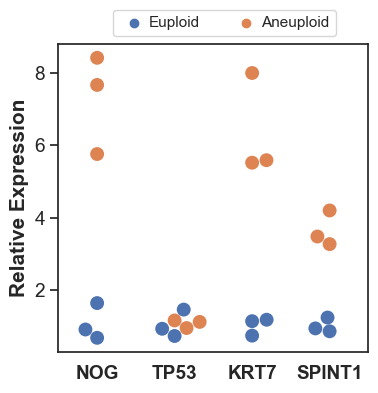

In [194]:
ploid_types = ['Euploid', 'Aneuploid']
ploid = []
samples = []
assay_types = ['NOG', 'TP53', 'KRT7', 'SPINT1']
assays = []
for p in ploid_types:
    for j in range(0, 3):
        for assay in assay_types:
            ploid.append(p)
            samples.append(j + 1)
            assays.append(assay)
relex = [0.68,1.46,1.14,0.94,
        1.64,0.73,0.74,1.24,
        0.91,0.93,1.18,0.86,
        5.76,0.95,5.59,3.27,
        7.67,1.12,5.52,4.20,
        8.42,1.16,8.00,3.48]
df = pd.DataFrame({'Ploidy': ploid,
                  'Sample': samples,
                  'Assay': assays,
                  'RelEx': relex})
# print(df.head(20))

fig = plt.figure(figsize=(4, 4))
sns.set_style('white')
plt.rcParams['ytick.left'] = True

sns.swarmplot(x='Assay',
              y='RelEx',
              data= df,
              hue='Ploidy',
              size=10,
              palette='deep',
              zorder=1)

plt.legend(bbox_to_anchor=(0.15, 1),
           ncols=2,
           handletextpad=0,
           fontsize=11)
plt.xticks(fontweight='bold')
plt.xlabel('')
plt.ylabel('Relative Expression', fontweight='bold')

sns.set(font_scale=1.25)
# fig.tight_layout()